# 02 · Week-0 pilot: 48 fields, from label to X and y

**What a pilot is.** Before the team downloads imagery for about 10 000 fields, it runs the whole chain on a few
fields from every cohort and looks at each one. If a cohort breaks here, it is cheap to repair or drop.

**The 48 records** (`docs/DECISIONS.md`, 28 Oct): per cohort, the first rows of the audit file, split evenly over
harvest years — Malawi 2023 12, Kenya OAF 12 (6 + 6), Zimbabwe 2024 16, Zimbabwe Lacuna 8 (4 + 4).

**How to reproduce the inputs** (from the repository root):

```bash
python scripts/imagery/select_pilot.py      # writes configs/sentinel2_windows_pilot48.csv
python scripts/imagery/download_sentinel2.py download --datasets malawi_2023 one_acre_fund_full vision_guided_yield_estimation zimbabwe --date-overrides configs/sentinel2_windows_pilot48.csv --only-listed
```

**One field, one row, one y.** Every feature family starts from the same field and ends in the same row:

```
                           one field  (obs_id = dataset:source_id)
                ┌───────────────────────────┴───────────────────────────┐
          label row (audit CSV)                         chip: months × 10 bands × 64 × 64 pixels
          y = yield, kg/ha                                         │
                │                            ┌────────────────────┼─────────────────────┐
                │                       MOSAIKS:            field median per month → table months × 10 bands
                │                  random filters over               │                         │
                │                     the image             vegetation indices          Presto encoder
                │                         │                          │                         │
                ▼                         ▼                          ▼                         ▼
  one row:   obs_id  |  y  |      K MOSAIKS numbers    |    10 index numbers    |    128 Presto numbers
```

Latitude and longitude are used once, by the downloader, to place the 64 × 64 chip. After that, the key that joins
everything is `obs_id`.

**What the pilot checks per cohort** (`docs/ROADMAP.md`, gate on 1 Nov):

| Check | Question | Section |
|---|---|---|
| Y | Do we know the label's unit and where it comes from? | 3 |
| Pairing | Do label, season window and location fit together? | 3 |
| Coverage | How many months have a clear scene over the field? | 4, 5 |
| Tensor | Does every record give a valid Presto input? | 7 |
| Trainability | Does Presto fine-tuning run, get gradients and overfit 48 records? | 7 |

Pass: the cohort goes to the full download. Fail: repair it within the week or drop the cohort.

In [1]:
import json
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.transform import Affine
from rasterio.warp import transform_geom
from shapely.geometry import shape

from cropyield import ROOT
from cropyield.data.cohorts import load_cohort
from cropyield.features.presto_inputs import NORMED_BANDS, SENTINEL2_TO_PRESTO, presto_inputs
from cropyield.longpath import filesystem_path, path_exists
from cropyield.models.presto import encode, load_presto, to_tensors
from cropyield.models.presto_single_file import BANDS_GROUPS_IDX
from cropyield.satellite.chips import read_chip
from cropyield.satellite.monthly import month_range, monthly_series

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 9})
IMAGERY = ROOT / "data" / "imagery" / "sentinel2"
CARDS = ROOT / "data" / "runs" / "pilot48" / "cards"     # git-ignored, regenerated by this notebook
PILOT_FILE = ROOT / "configs" / "sentinel2_windows_pilot48.csv"
COHORT_ORDER = ["malawi_2023", "kenya_oaf_2019_2020", "zimbabwe_2024", "zimbabwe_lacuna_2022_2023"]
SHORT = {"malawi_2023": "Malawi 2023", "kenya_oaf_2019_2020": "Kenya OAF", "zimbabwe_2024": "Zimbabwe 2024",
         "zimbabwe_lacuna_2022_2023": "Zim. Lacuna"}

## 1. The selection

The window file names each record and its fixed season window. `load_cohort` gives the label row of each record;
the two tables join on `(dataset, source_id)`.

In [2]:
def label_date(row):
    """Harvest or crop-cut date of a label row, whichever the source has (None if neither)."""
    for column in ("harvest_date", "observation_time"):
        text = row.get(column)
        if isinstance(text, str) and text.strip():
            return date.fromisoformat(text.strip()[:10].replace("/", "-"))
    return None


windows = pd.read_csv(PILOT_FILE, dtype=str)
labels = pd.concat([load_cohort(name) for name in COHORT_ORDER], ignore_index=True)
pilot = windows.merge(labels, on=["dataset", "source_id"], how="left", validate="one_to_one", suffixes=("", "_cohort"))
assert pilot["obs_id"].notna().all() and (pilot["cohort"] == pilot["cohort_cohort"]).all()
pilot["window_start"] = pilot["start_date"].map(date.fromisoformat)
pilot["window_end"] = pilot["end_date"].map(date.fromisoformat)
pilot["label_date"] = [label_date(r) for _, r in pilot.iterrows()]
pilot = pilot.set_index("obs_id")
print(f"{len(pilot)} records from {PILOT_FILE.relative_to(ROOT)}")
pilot.groupby(["cohort", "year"], sort=False).size().to_frame("records")

48 records from configs\sentinel2_windows_pilot48.csv


records
cohort                    year         
malawi_2023               2023       12
kenya_oaf_2019_2020       2019        6
                          2020        6
zimbabwe_2024             2024       16
zimbabwe_lacuna_2022_2023 2022        4
                          2023        4

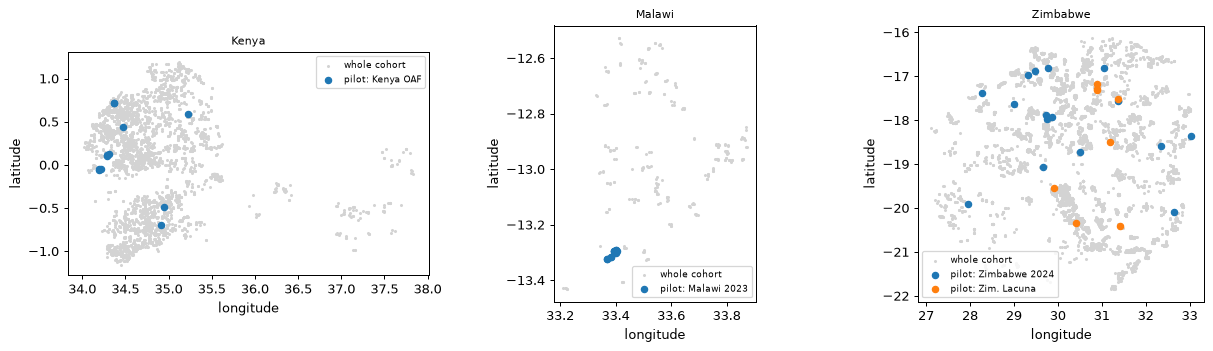

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, country in zip(axes, ["kenya", "malawi", "zimbabwe"]):
    everyone = labels[labels["country"] == country]
    ax.scatter(everyone["longitude"], everyone["latitude"], s=2, color="lightgrey", label="whole cohort")
    for cohort, group in pilot[pilot["country"] == country].groupby("cohort"):
        ax.scatter(group["longitude"], group["latitude"], s=25, label=f"pilot: {SHORT[cohort]}")
    ax.set(title=country.title(), xlabel="longitude", ylabel="latitude", aspect="equal")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 2. What the downloader wrote

One folder per record under `data/imagery/sentinel2/run-*/records/`. `record.json` says how many scenes the
catalogue had in the window, how many months were accepted, and whether the field fits inside the chip.

In [4]:
def record_folder(dataset, source_id, window):
    """The record folder whose search window equals the pilot window (the newest run if several)."""
    safe_id = re.sub(r"[^A-Za-z0-9_-]", "_", source_id)[:64]
    for folder in sorted(IMAGERY.glob(f"run-*/records/{dataset}__{safe_id}__*"), reverse=True):
        if path_exists(folder / "record.json"):
            record = json.loads(Path(filesystem_path(folder / "record.json")).read_text())
            if (record["record"]["start_date"], record["record"]["end_date"]) == window:
                return folder, record
    raise FileNotFoundError(f"{dataset}:{source_id} has no record folder; run the download command above")


folders, records = {}, {}
for obs_id, r in pilot.iterrows():
    folders[obs_id], records[obs_id] = record_folder(r["dataset"], r["source_id"], (r["start_date"], r["end_date"]))
download = pd.DataFrame({
    "cohort": pilot["cohort"],
    "status": [records[i]["status"] for i in pilot.index],
    "aoi": [records[i]["aoi_type"] for i in pilot.index],
    "aoi_inside_chip": [records[i]["entire_aoi_inside_chip"] for i in pilot.index],
    "catalog_scenes": [records[i]["catalog_matches"] for i in pilot.index],
    "accepted_months": [len(records[i]["accepted_item_ids"]) for i in pilot.index],
}, index=pilot.index)
download.groupby("cohort", sort=False).agg(
    records=("status", "size"), complete=("status", lambda s: int((s == "complete").sum())),
    other_status=("status", lambda s: ", ".join(f"{k} {v}" for k, v in s[s != "complete"].value_counts().items())),
    aoi=("aoi", "first"), catalog_scenes_median=("catalog_scenes", "median"),
    accepted_months_median=("accepted_months", "median"), accepted_months_min=("accepted_months", "min"))

,records,complete,other_status,aoi,catalog_scenes_median,accepted_months_median,accepted_months_min
cohort,,,,,,,
malawi_2023,12,12,,field_polygon,50.0,5.0,4
kenya_oaf_2019_2020,12,12,,point_pixel,42.5,7.5,7
zimbabwe_2024,16,16,,point_pixel,48.0,9.0,8
zimbabwe_lacuna_2022_2023,8,8,,point_pixel,23.5,5.0,3


## 3. Y and pairing

* **Y**: the provider column, its unit, and the value in kg/ha.
* **Pairing**: the season window is fixed per agro-zone. The harvest or crop-cut date should fall inside it;
  a date after the window end means the window cuts off the end of the season. The field (or point) must lie
  inside the chip.

In [5]:
pairing = pd.DataFrame({
    "cohort": pilot["cohort"],
    "yield_field": pilot["yield_field"],
    "unit": pilot["source_yield_units"],
    "yield_kg_ha": pilot["yield_kg_ha"],
    "window": pilot["start_date"] + " .. " + pilot["end_date"],
    "label_date": pilot["label_date"],
    "label_date_in_window": [d is not None and s <= d <= e
                             for d, s, e in zip(pilot["label_date"], pilot["window_start"], pilot["window_end"])],
    "aoi_inside_chip": download["aoi_inside_chip"],
}, index=pilot.index)
pairing.groupby("cohort", sort=False).agg(
    yield_field=("yield_field", "first"), unit=("unit", "first"),
    zero_yields=("yield_kg_ha", lambda s: int((s == 0).sum())), median_kg_ha=("yield_kg_ha", "median"),
    window=("window", lambda s: ", ".join(sorted(set(s)))),
    label_dates=("label_date", lambda s: f"{min(d for d in s if d)} .. {max(d for d in s if d)}" if s.notna().any()
                 else "none"),
    label_date_in_window=("label_date_in_window", "sum"), aoi_inside_chip=("aoi_inside_chip", "sum"))

,yield_field,unit,zero_yields,median_kg_ha,window,label_dates,label_date_in_window,aoi_inside_chip
cohort,,,,,,,,
malawi_2023,cc_ey_t,t/ha,0,2905.00000,2022-10-01 .. 2023-06-30,2023-05-17 .. 2023-05-17,12,12
kenya_oaf_2019_2020,yield_kg_ph,kg/ha,3,2007.24075,"2019-02-01 .. 2019-09-30, 2020-02-01 .. 2020-0...",2019-07-15 .. 2020-10-15,11,12
zimbabwe_2024,Avg_yield_mt_ha,t/ha,7,137.81250,2023-10-01 .. 2024-06-30,2024-04-13 .. 2024-06-25,16,16
zimbabwe_lacuna_2022_2023,Yield(Mt/H,t/ha,0,3372.50000,"2021-10-01 .. 2022-06-30, 2022-10-01 .. 2023-0...",2022-06-24 .. 2023-05-05,6,8


## 4. Coverage: which months have a usable scene

One cell per record and month of its window:

* **no scene**: the catalogue offers no scene of this tile in that month with tile cloud cover ≤ 80 % (the
  downloader's `--max-cloud-cover`). For Oct–Nov 2022 and Jan–Jun 2022 the cause is a real gap: Earth Search
  Collection 1 holds no scene there even without that limit (checked 29 Oct 2026).
* **cloudy**: up to three scenes were tried; none had 80 % clear field pixels.
* **clear**: one scene accepted.
* **clear?, bright blue**: accepted by SCL, but more than 10 % of the field pixels have blue reflectance above 0.12.
  Over a green crop this is haze that SCL missed (see `00_data_tour.ipynb`, section 6). Over bright, dry soil it is
  not: most Zimbabwe 2024 flags are bare sandy soil between October and January (look at the cards). So it is a
  flag for the eye, not a mask.

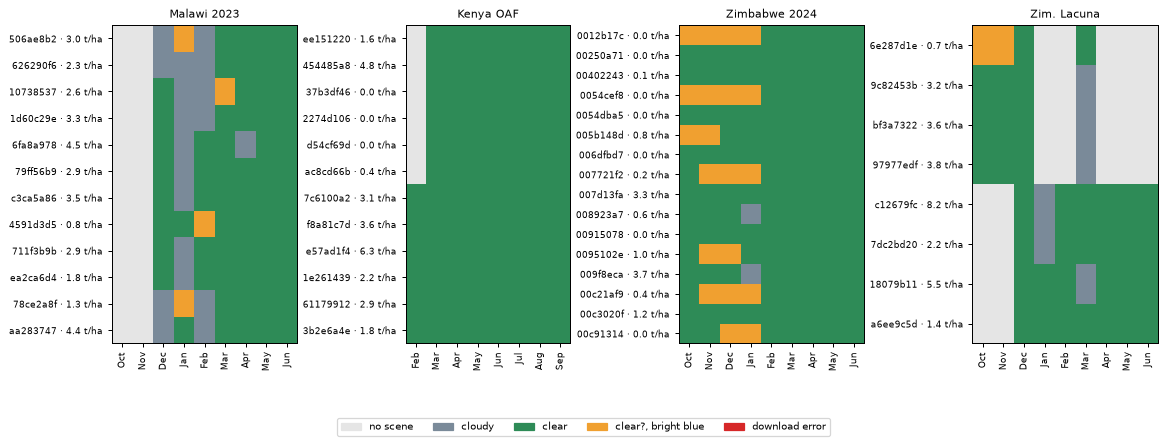

,no scene,cloudy,clear,"clear?, bright blue",download error,months_in_windows
cohort,,,,,,
malawi_2023,24,19,61,4,0,108
kenya_oaf_2019_2020,6,0,90,0,0,96
zimbabwe_2024,0,2,122,20,0,144
zimbabwe_lacuna_2022_2023,28,6,36,2,0,72


In [6]:
BLUE_FLAG = 0.12
STATES = ["no scene", "cloudy", "clear", "clear?, bright blue", "download error"]
STATE_COLOURS = ["#e5e5e5", "#7a8a99", "#2e8b57", "#f0a030", "#d62728"]

chips, series = {}, {}
for obs_id, r in pilot.iterrows():
    chips[obs_id] = read_chip(folders[obs_id])
    if chips[obs_id].scenes and chips[obs_id].status not in ("error", "partial_error"):
        series[obs_id] = monthly_series(chips[obs_id], r["window_start"], r["window_end"])


def bright_blue(chip, scene):
    field = chip.aoi_interior if chip.aoi_interior.any() else chip.aoi
    return float((scene.reflectance[chip.bands.index("B02")][field] > BLUE_FLAG).mean()) > 0.1


def month_states(obs_id):
    record, chip = records[obs_id], chips[obs_id]
    attempts = pd.DataFrame(record["attempts"], columns=["month", "status", "item_id"])
    by_item = {s.item_id: s for s in chip.scenes}
    states = {}
    for month in month_range(pilot.at[obs_id, "window_start"], pilot.at[obs_id, "window_end"]):
        tried = attempts[attempts["month"] == month]
        accepted = tried[tried["status"] == "accepted"]
        if len(accepted):
            states[month] = 3 if bright_blue(chip, by_item[accepted["item_id"].iloc[0]]) else 2
        elif (tried["status"] == "error").any():
            states[month] = 4
        else:
            states[month] = 1 if len(tried) else 0
    return states


coverage = {obs_id: month_states(obs_id) for obs_id in pilot.index}
fig, axes = plt.subplots(1, 4, figsize=(15, 5.2), gridspec_kw={"width_ratios": [9, 8, 9, 9]})
for ax, cohort in zip(axes, COHORT_ORDER):
    ids = list(pilot.index[pilot["cohort"] == cohort])
    grid = np.array([list(coverage[i].values()) for i in ids])          # same window length within a cohort
    ax.imshow(grid, cmap=ListedColormap(STATE_COLOURS), vmin=-0.5, vmax=4.5, aspect="auto")
    month_names = [date(2000, int(m[5:]), 1).strftime("%b") for m in coverage[ids[0]]]
    ax.set_xticks(range(grid.shape[1]), month_names, rotation=90, fontsize=7)
    ax.set_yticks(range(len(ids)), [f"{i.split(':')[1][:8]} · {pilot.at[i, 'yield_kg_ha'] / 1000:.1f} t/ha" for i in ids],
                  fontsize=7)
    ax.set_title(SHORT[cohort])
fig.legend(handles=[Patch(color=c, label=s) for s, c in zip(STATES, STATE_COLOURS)], loc="lower center", ncol=5,
           fontsize=8)
plt.subplots_adjust(bottom=0.2, wspace=0.6)
plt.show()

summary = pd.DataFrame([{"cohort": pilot.at[i, "cohort"], **{s: sum(v == k for v in coverage[i].values())
                         for k, s in enumerate(STATES)}} for i in pilot.index]).groupby("cohort", sort=False).sum()
summary["months_in_windows"] = summary.sum(axis=1)
summary

## 5. Inspection cards

One card per record: the label on the left; one true-colour thumbnail per month of the window (outline for a
polygon, a cross for a point); below, the clear field pixels per month and the NDVI curve. All 48 cards are written
to `data/runs/pilot48/cards/` (git-ignored); one card per cohort is shown here, then a contact sheet of all 48.

48 cards written to data\runs\pilot48\cards


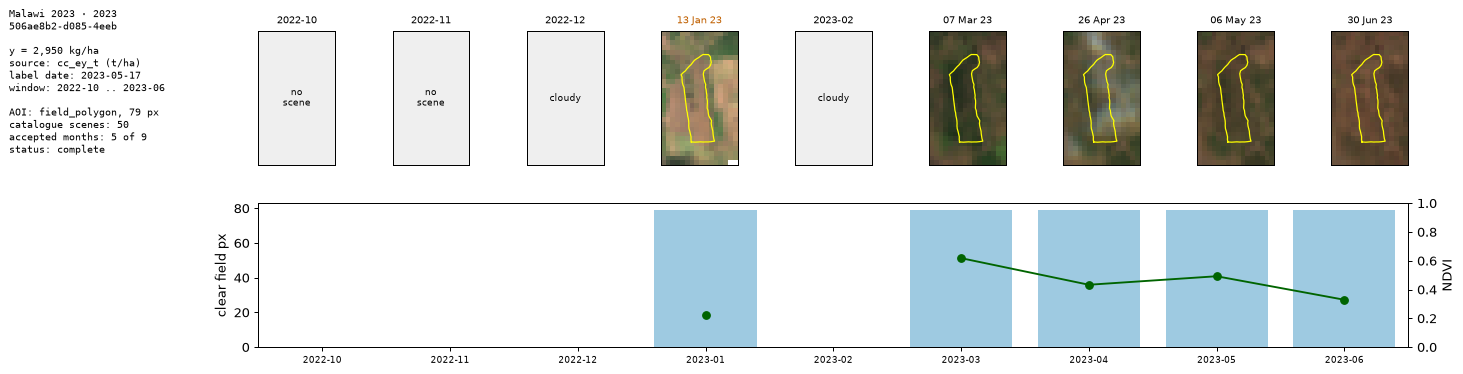

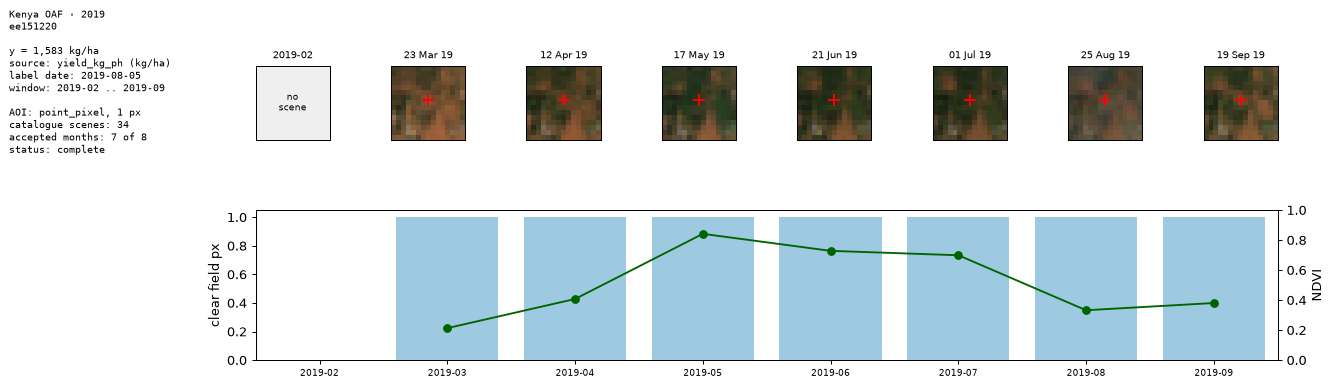

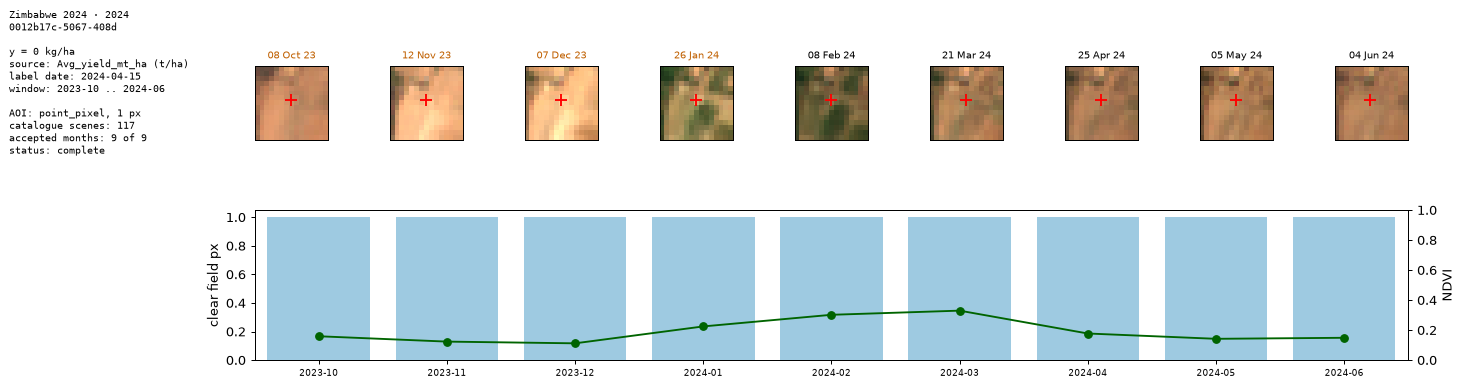

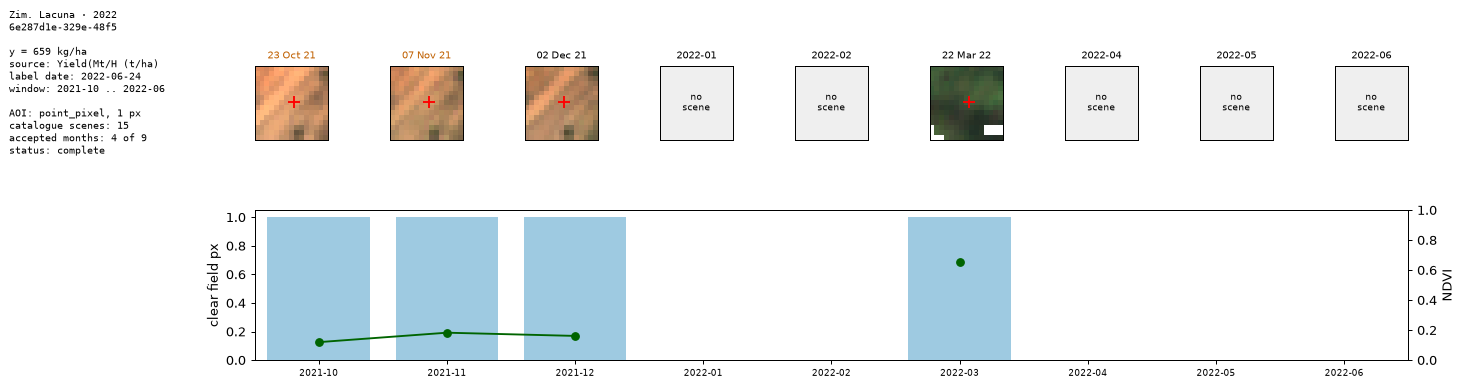

In [7]:
def composite(scene, chip, top=0.3):
    image = np.stack([scene.reflectance[chip.bands.index(b)] for b in ("B04", "B03", "B02")], axis=-1) / top
    return np.nan_to_num(np.clip(image, 0, 1), nan=1.0)


def outline_pixels(geometry, chip):
    """Rings (polygon) or one point in chip pixel coordinates, ready to draw over imshow."""
    projected = shape(transform_geom("EPSG:4326", chip.crs, geometry))
    to_pixel = ~Affine(*chip.transform)
    if projected.geom_type == "Point":
        column, row_ = to_pixel * (projected.x, projected.y)
        return "point", (column - 0.5, row_ - 0.5)
    parts = projected.geoms if projected.geom_type == "MultiPolygon" else [projected]
    return "polygon", [tuple(np.array(v) - 0.5 for v in zip(*(to_pixel * xy for xy in p.exterior.coords))) for p in parts]


def draw_aoi(ax, obs_id):
    kind, shape_px = outline_pixels(records[obs_id]["record"]["geometry"], chips[obs_id])
    if kind == "point":
        ax.plot(*shape_px, marker="+", color="red", markersize=10, mew=1.5)
    else:
        for columns, rows_ in shape_px:
            ax.plot(columns, rows_, color="yellow", lw=1)


def zoom(ax, chip):
    rows_in, cols_in = np.where(chip.aoi)
    pad = 4 if chip.aoi_type == "field_polygon" else 7
    ax.set(xlim=(cols_in.min() - pad - 0.5, cols_in.max() + pad + 0.5),
           ylim=(rows_in.max() + pad + 0.5, rows_in.min() - pad - 0.5), xticks=[], yticks=[])


def peak_scene(obs_id):
    """The accepted scene with the highest field NDVI (None without scenes)."""
    chip = chips[obs_id]
    field = chip.aoi_interior if chip.aoi_interior.any() else chip.aoi

    def ndvi(scene):
        nir, red = scene.reflectance[chip.bands.index("B08")], scene.reflectance[chip.bands.index("B04")]
        value = np.nanmedian(((nir - red) / (nir + red))[field])
        return -np.inf if np.isnan(value) else value
    return max(chip.scenes, key=ndvi) if chip.scenes else None


def card(obs_id):
    r, chip, record = pilot.loc[obs_id], chips[obs_id], records[obs_id]
    months = month_range(r["window_start"], r["window_end"])
    by_month = {s.date.strftime("%Y-%m"): s for s in chip.scenes}
    fig = plt.figure(figsize=(3.4 + 1.45 * len(months), 4.4))
    grid = fig.add_gridspec(2, len(months) + 1, width_ratios=[2.5] + [1] * len(months), height_ratios=[1.25, 1])
    text = fig.add_subplot(grid[:, 0])
    text.axis("off")
    text.text(0, 1, "\n".join([
        f"{SHORT[r['cohort']]} · {r['year']}", f"{obs_id.split(':')[1][:18]}", "",
        f"y = {r['yield_kg_ha']:,.0f} kg/ha", f"source: {r['yield_field']} ({r['source_yield_units']})",
        f"label date: {r['label_date']}", f"window: {r['start_date'][:7]} .. {r['end_date'][:7]}", "",
        f"AOI: {chip.aoi_type}, {int(chip.aoi_interior.sum() if chip.aoi_interior.any() else chip.aoi.sum())} px",
        f"catalogue scenes: {record['catalog_matches']}", f"accepted months: {len(chip.scenes)} of {len(months)}",
        f"status: {record['status']}"]), va="top", fontsize=8, family="monospace")
    for k, month in enumerate(months):
        ax = fig.add_subplot(grid[0, k + 1])
        state = STATES[coverage[obs_id][month]]
        if month in by_month:
            ax.imshow(composite(by_month[month], chip))
            draw_aoi(ax, obs_id)
            zoom(ax, chip)
            ax.set_title(f"{by_month[month].date:%d %b %y}", fontsize=8,
                         color="#c06000" if state.startswith("clear?") else "black")
        else:
            ax.imshow(np.full(chip.aoi.shape + (3,), 0.94))                    # same size as an image tile
            zoom(ax, chip)
            ax.text(0.5, 0.5, state.replace(" ", "\n"), ha="center", va="center", fontsize=7, transform=ax.transAxes)
            ax.set_title(month, fontsize=8)
    bars = fig.add_subplot(grid[1, 1:])
    s = series.get(obs_id)
    pixels = s.n_pixels if s is not None else np.zeros(len(months))
    bars.bar(range(len(months)), pixels, color="#9ecae1")
    bars.set(xticks=range(len(months)), xlim=(-0.5, len(months) - 0.5), ylabel="clear field px")
    bars.set_xticklabels(months, fontsize=7)
    if s is not None:
        line = bars.twinx()
        ndvi = (s.band("B08") - s.band("B04")) / (s.band("B08") + s.band("B04"))
        line.plot(range(len(months)), ndvi, marker="o", color="darkgreen")
        line.set(ylim=(0, 1), ylabel="NDVI")
    fig.tight_layout()
    return fig


CARDS.mkdir(parents=True, exist_ok=True)
for obs_id in pilot.index:
    figure = card(obs_id)
    figure.savefig(CARDS / f"{obs_id.replace(':', '__')}.png", dpi=80)
    plt.close(figure)
print(f"{len(pilot)} cards written to {CARDS.relative_to(ROOT)}")
for cohort in COHORT_ORDER:
    card(pilot.index[pilot["cohort"] == cohort][0])
    plt.show()

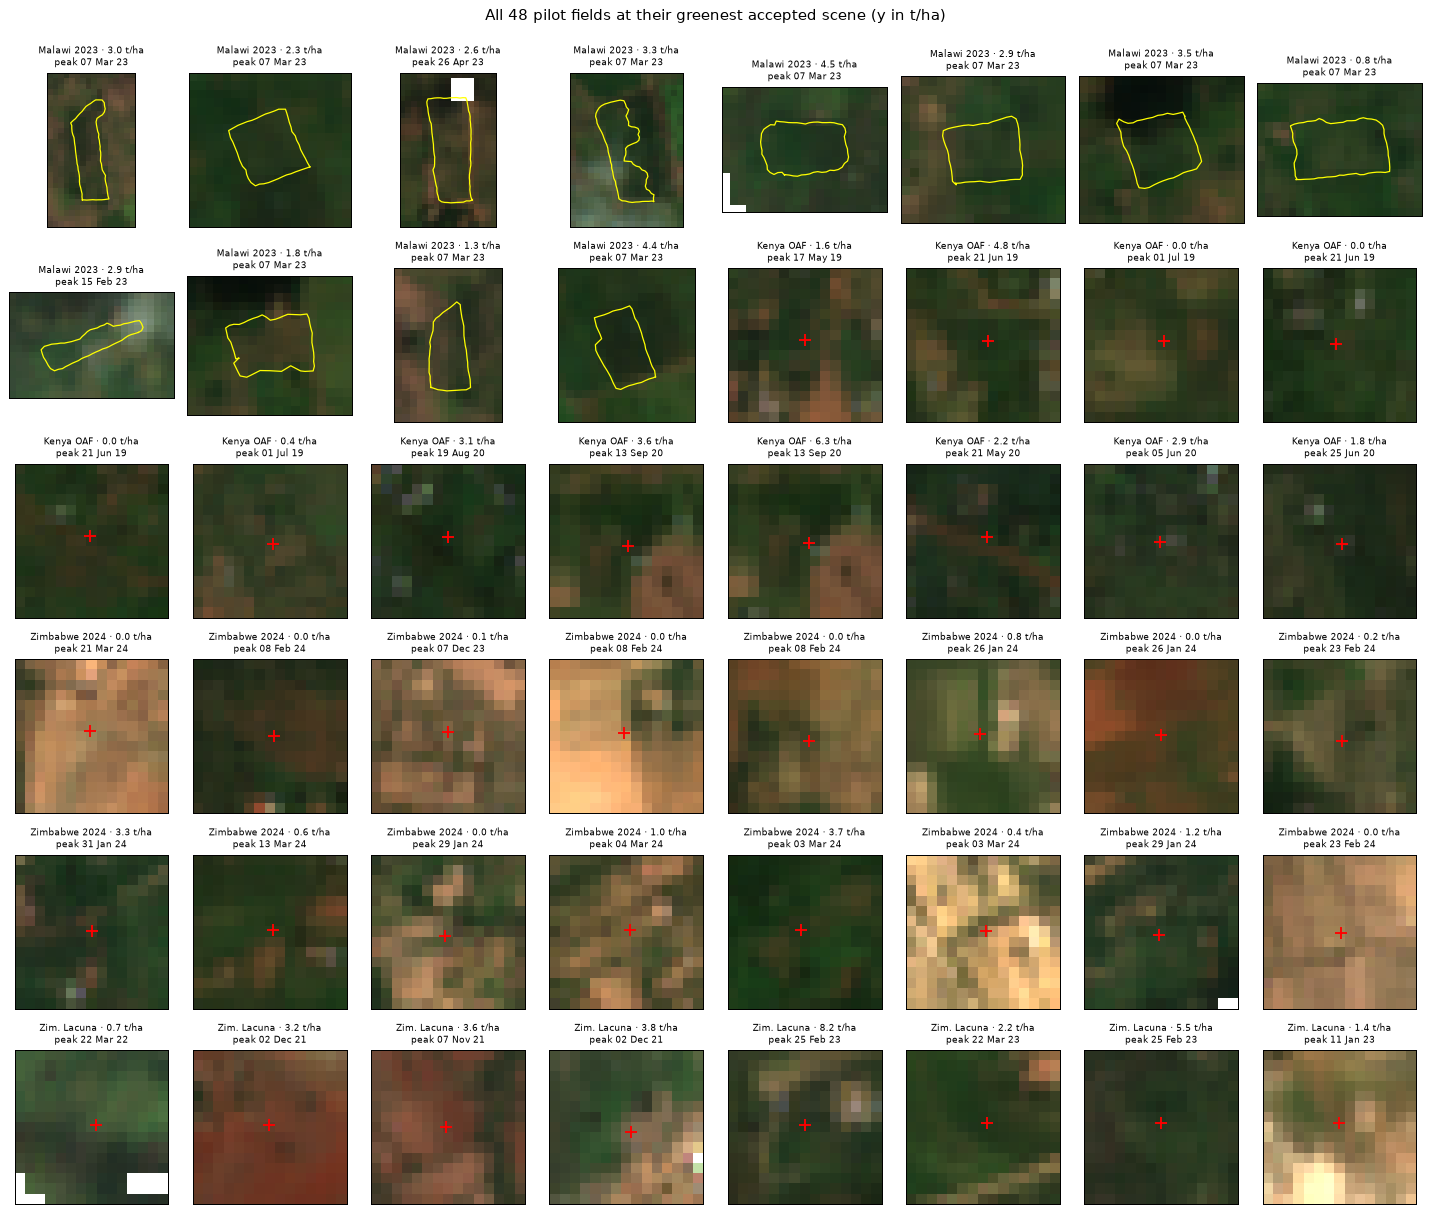

In [8]:
fig, axes = plt.subplots(6, 8, figsize=(16, 13.5))
for ax, obs_id in zip(axes.flat, pilot.index):
    scene = peak_scene(obs_id)
    if scene is None:
        ax.set(facecolor="#f2f2f2", xticks=[], yticks=[])
        ax.text(0.5, 0.5, "no clear scene", ha="center", va="center", fontsize=8, transform=ax.transAxes)
    else:
        ax.imshow(composite(scene, chips[obs_id]))
        draw_aoi(ax, obs_id)
        zoom(ax, chips[obs_id])
    ax.set_title(f"{SHORT[pilot.at[obs_id, 'cohort']]} · {pilot.at[obs_id, 'yield_kg_ha'] / 1000:.1f} t/ha"
                 + (f"\npeak {scene.date:%d %b %y}" if scene is not None else ""), fontsize=7)
fig.suptitle("All 48 pilot fields at their greenest accepted scene (y in t/ha)", y=0.995)
plt.tight_layout()
plt.show()

## 6. X and y: three feature families, one row per field, the same y

Each family below turns the same chip into numbers, keyed by `obs_id`:

* **Vegetation indices** (Lobell et al. 2020, Table 2) per month, then seasonal max and mean: 10 numbers. The final
  seasonal summary is still the baseline owner's choice.
* **Presto**: the monthly table becomes `x` + `mask`; the frozen encoder gives 128 numbers.
* **MOSAIKS**: the features of `scripts/features/mosaiks_features.py` (Rolf et al. 2021): 512 whitened random
  3 × 3 × 10 patches as filters, ReLU of the response and of its negative, averaged over the 640 m chip of each
  accepted month, then averaged over the season: K = 1024 numbers. The `field` pooling (field pixels only) is in
  the same file and in the database.

Records without any usable month have no X and drop out here.

In [9]:
def vegetation_indices(s):
    b = {code: s.band(code) for code in s.bands}
    return pd.DataFrame({
        "NDVI": (b["B08"] - b["B04"]) / (b["B08"] + b["B04"]),
        "GCVI": b["B08"] / b["B03"] - 1,
        "MTCI": (b["B08"] - b["B05"]) / (b["B05"] - b["B04"]),
        "NDVI705": (b["B08"] - b["B05"]) / (b["B08"] + b["B05"]),
        "NDVI740": (b["B08"] - b["B06"]) / (b["B08"] + b["B06"]),
    }, index=s.months)


def seasonal_summary(indices):
    stats = indices.agg(["max", "mean"])
    return pd.Series({f"{name}_{stat}": stats.loc[stat, name] for name in indices.columns for stat in stats.index})


usable = [i for i in pilot.index if i in series and (~series[i].missing).any()]
inputs = {i: presto_inputs(series[i], pilot.at[i, "latitude"], pilot.at[i, "longitude"]) for i in usable}
model = load_presto()
X_indices = pd.DataFrame({i: seasonal_summary(vegetation_indices(series[i])) for i in usable}).T
X_presto = pd.DataFrame({i: encode(model, inputs[i]) for i in usable}).T.add_prefix("presto_")

mosaiks_season = pd.read_parquet(ROOT / "data" / "features" / "mosaiks" / "season.parquet").set_index("obs_id")
X_mosaiks = pd.DataFrame(np.stack(mosaiks_season.loc[usable, "chip"].to_numpy()), index=usable).add_prefix("mosaiks_")
y = pilot.loc[usable, "yield_kg_ha"]
table = pd.concat([pilot.loc[usable, ["cohort"]], y, X_indices, X_presto, X_mosaiks], axis=1)
print(f"y {y.shape} | X_indices {X_indices.shape} | X_presto {X_presto.shape} | X_mosaiks {X_mosaiks.shape} "
      f"| joined table {table.shape}: one row per field (a few of the columns shown)")
table[["cohort", "yield_kg_ha", "NDVI_max", "NDVI_mean", "GCVI_max", "presto_0", "presto_1", "presto_127",
       "mosaiks_0", "mosaiks_1023"]].head(8).round(3)

y (48,) | X_indices (48, 10) | X_presto (48, 128) | X_mosaiks (48, 1024) | joined table (48, 1164): one row per field (a few of the columns shown)


,cohort,yield_kg_ha,NDVI_max,NDVI_mean,GCVI_max,presto_0,presto_1,presto_127,mosaiks_0,mosaiks_1023
malawi_2023:506ae8b2-d085-4eeb-b807-765e03925c71,malawi_2023,2950.0,0.618,0.420,2.870,-0.872,-4.672,1.339,2.110,1.903
malawi_2023:626290f6-99b2-4a44-b233-8df0e13d3e63,malawi_2023,2300.0,0.729,0.499,3.385,-0.699,-4.596,1.539,0.613,1.731
malawi_2023:10738537-aded-4abe-bc18-e3d8ce52f7f7,malawi_2023,2620.0,0.569,0.401,2.630,-0.949,-4.733,1.015,1.177,2.102
malawi_2023:1d60c29e-ee3a-4639-9e07-0239523dfc62,malawi_2023,3310.0,0.722,0.458,3.316,-0.996,-4.742,1.214,0.896,2.456
malawi_2023:6fa8a978-4710-469b-b593-e100746035dd,malawi_2023,4510.0,0.786,0.498,4.101,-1.345,-5.008,0.940,2.884,1.754
malawi_2023:79ff56b9-ea86-438b-ad8b-6859295353db,malawi_2023,2880.0,0.669,0.474,2.575,-1.284,-4.822,1.137,2.109,1.733
malawi_2023:c3ca5a86-2c24-4c45-a762-9c766fb0fb1d,malawi_2023,3450.0,0.775,0.504,3.989,-1.206,-4.875,0.922,2.077,1.925
malawi_2023:4591d3d5-8258-4a9e-a8db-ad1024acb672,malawi_2023,780.0,0.683,0.462,2.519,-1.170,-4.949,0.775,2.720,1.642


The picture below is that table. Each row is one field. Left: its y. Then its three blocks of X, every column
standardised so the colours are comparable. Rows are grouped by cohort and sorted by yield inside each cohort.
Reading across one row shows the point of the whole pipeline: **three different descriptions of the same chip,
and one label**.

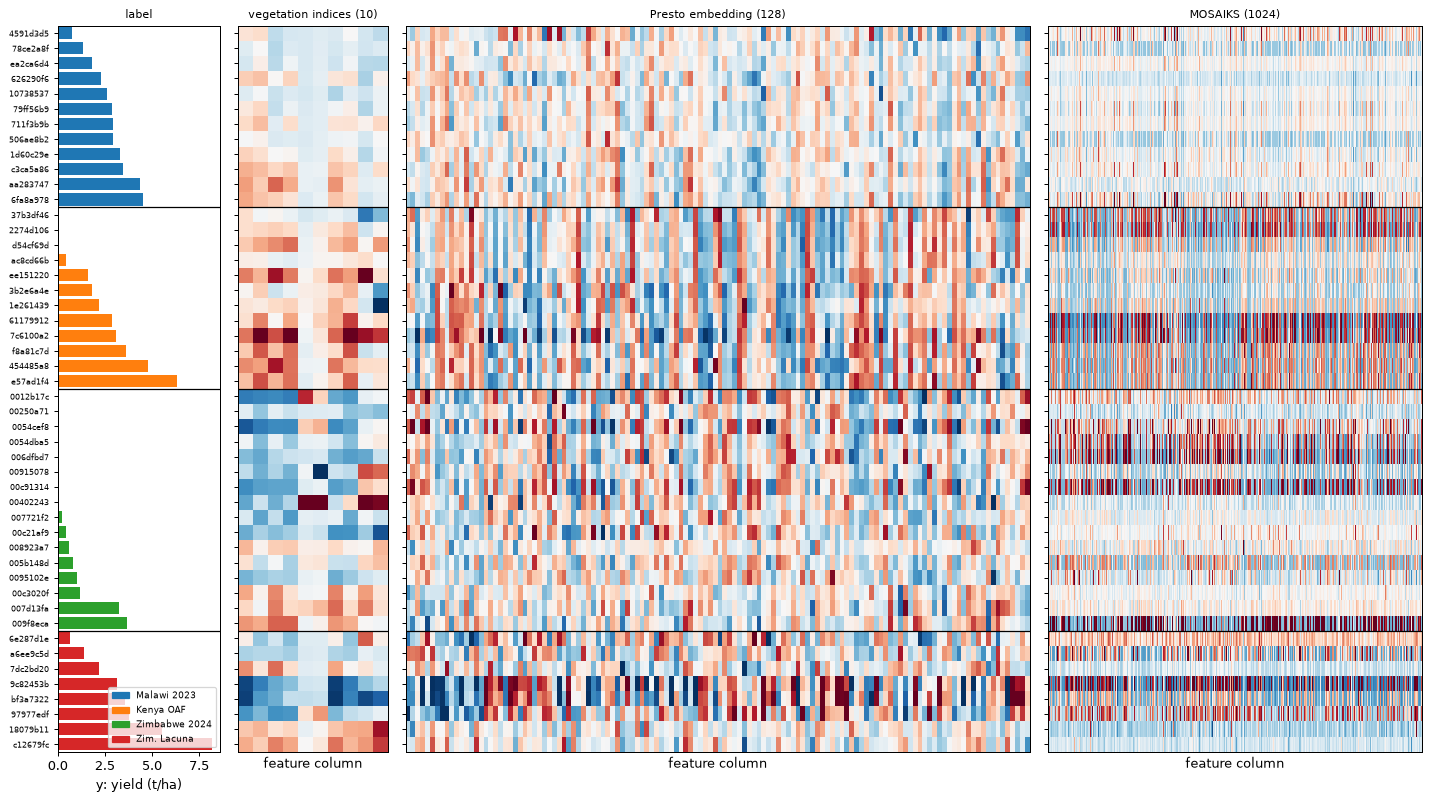

In [10]:
order = table.assign(_c=table["cohort"].map(COHORT_ORDER.index)).sort_values(["_c", "yield_kg_ha"]).index
blocks = [("vegetation indices (10)", X_indices), ("Presto embedding (128)", X_presto), ("MOSAIKS (1024)", X_mosaiks)]
fig, axes = plt.subplots(1, 4, figsize=(16, 9), gridspec_kw={"width_ratios": [1.3, 1.2, 5, 3]}, sharey=True)
axes[0].barh(range(len(order)), y.loc[order] / 1000, color=[f"C{COHORT_ORDER.index(c)}" for c in table.loc[order, "cohort"]])
axes[0].set(xlabel="y: yield (t/ha)", title="label")
axes[0].set_yticks(range(len(order)), [i.split(":")[1][:8] for i in order], fontsize=6)
for ax, (title, block) in zip(axes[1:], blocks):
    values = block.loc[order].astype(float)
    z = ((values - values.mean()) / values.std().replace(0, 1)).to_numpy()
    ax.imshow(z, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, interpolation="nearest")
    ax.set(title=title, xlabel="feature column", xticks=[])
for ax in axes:
    for boundary in np.flatnonzero(np.diff(table.loc[order, "cohort"].map(COHORT_ORDER.index).to_numpy())) + 0.5:
        ax.axhline(boundary, color="black", lw=1)
axes[0].set_ylim(len(order) - 0.5, -0.5)                                   # first row at the top
axes[0].legend(handles=[Patch(color=f"C{k}", label=SHORT[c]) for k, c in enumerate(COHORT_ORDER)], fontsize=7,
               loc="lower right")
plt.tight_layout()
plt.show()

## 7. Tensor and trainability

**Tensor check**, per record: `x` and `mask` have shape (1, months, 17); every value is finite; masked slots are 0;
the Sentinel-2 slots equal the monthly table (so band order and scale are right); and the token count by the
encoder's rule equals the count the real encoder returns.

In [11]:
def tensor_check(obs_id):
    inp, s = inputs[obs_id], series[obs_id]
    slots_match = all(np.allclose(inp.x[0, ~s.missing, NORMED_BANDS.index(name)], s.band(code)[~s.missing])
                      for code, name in SENTINEL2_TO_PRESTO.items())
    expected = 1 + sum(int((inp.mask[0][:1 if g == "SRTM" else None, idx].max(axis=1) == 0).sum())
                       for g, idx in BANDS_GROUPS_IDX.items())
    with torch.no_grad():
        tokens = model.encoder(**to_tensors(inp), eval_task=False)[0].shape[1]
    return {"cohort": pilot.at[obs_id, "cohort"], "shape_ok": inp.x.shape == (1, len(s.months), 17) == inp.mask.shape,
            "finite": bool(np.isfinite(inp.x).all()), "masked_are_zero": bool((inp.x[inp.mask == 1] == 0).all()),
            "bands_match_table": slots_match, "tokens": tokens, "tokens_match_rule": tokens == expected}


tensors = pd.DataFrame({i: tensor_check(i) for i in usable}).T
tensors.groupby("cohort", sort=False).agg(
    records=("tokens", "size"), shape_ok=("shape_ok", "sum"), finite=("finite", "sum"),
    masked_are_zero=("masked_are_zero", "sum"), bands_match_table=("bands_match_table", "sum"),
    tokens_match_rule=("tokens_match_rule", "sum"), tokens_min=("tokens", "min"), tokens_max=("tokens", "max"))

,records,shape_ok,finite,masked_are_zero,bands_match_table,tokens_match_rule,tokens_min,tokens_max
cohort,,,,,,,,
malawi_2023,12,12,12,12,12,12,25,43
kenya_oaf_2019_2020,12,12,12,12,12,12,43,49
zimbabwe_2024,16,16,16,16,16,16,49,55
zimbabwe_lacuna_2022_2023,8,8,8,8,8,8,19,43


**Trainability smoke test.** A *second* copy of Presto (fine-tuning changes the encoder in place) gets the official
regression head and is trained on all usable pilot records, one record per step (records have different numbers of
masked tokens). y is standardised. This is **not a result**: it trains and evaluates on the same records. It only
checks that the loss is finite, the encoder receives gradients, and the model can memorise the pilot.

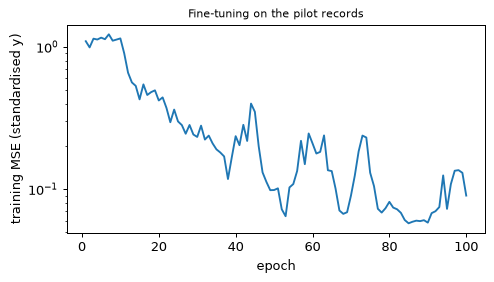

records 48 | first-epoch MSE 1.097 | last-epoch MSE 0.0903 | all finite: True | encoder gradient norm at step 1: 6.0830


In [12]:
torch.manual_seed(291)
finetune = load_presto().construct_finetuning_model(num_outputs=1, regression=True)
target = {i: torch.tensor([[(y[i] - y.mean()) / y.std()]], dtype=torch.float32) for i in usable}
optimiser = torch.optim.AdamW(finetune.parameters(), lr=1e-3)
EPOCHS, history, encoder_gradient = 100, [], None
for epoch in range(EPOCHS):
    losses = []
    for obs_id in usable:
        loss = F.mse_loss(finetune(**to_tensors(inputs[obs_id])), target[obs_id])
        optimiser.zero_grad()
        loss.backward()
        if encoder_gradient is None:
            encoder_gradient = float(sum(p.grad.norm() ** 2 for p in finetune.encoder.parameters()
                                         if p.grad is not None) ** 0.5)
        optimiser.step()
        losses.append(loss.item())
    history.append(float(np.mean(losses)))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, EPOCHS + 1), history)
ax.set(yscale="log", xlabel="epoch", ylabel="training MSE (standardised y)", title="Fine-tuning on the pilot records")
plt.show()
print(f"records {len(usable)} | first-epoch MSE {history[0]:.3f} | last-epoch MSE {history[-1]:.4f} | "
      f"all finite: {bool(np.isfinite(history).all())} | encoder gradient norm at step 1: {encoder_gradient:.4f}")

## 8. Gate summary per cohort

The facts from sections 2–7 side by side. The team reads this table at the 1 Nov gate.

In [13]:
gate = pd.DataFrame({
    "records": pilot.groupby("cohort", sort=False).size(),
    "Y: unit": pairing.groupby("cohort", sort=False)["unit"].first(),
    "Y: zero yields": pairing.groupby("cohort", sort=False)["yield_kg_ha"].apply(lambda s: int((s == 0).sum())),
    "pairing: label date in window": pairing.groupby("cohort", sort=False)["label_date_in_window"].sum(),
    "pairing: AOI inside chip": pairing.groupby("cohort", sort=False)["aoi_inside_chip"].sum(),
    "coverage: records with >= 1 month": pd.Series({c: sum(i in usable for i in pilot.index[pilot["cohort"] == c])
                                                   for c in COHORT_ORDER}),
    "coverage: median clear months": pd.Series({c: np.median([sum(v in (2, 3) for v in coverage[i].values())
                                                              for i in pilot.index[pilot["cohort"] == c]])
                                                for c in COHORT_ORDER}),
    "coverage: bright-blue months": summary["clear?, bright blue"],
    "tensor: all checks pass": tensors.assign(ok=tensors[["shape_ok", "finite", "masked_are_zero", "bands_match_table",
                                                          "tokens_match_rule"]].all(axis=1))
                                      .groupby("cohort", sort=False)["ok"].sum(),
}).loc[COHORT_ORDER]
gate["tensor: all checks pass"] = gate["tensor: all checks pass"].fillna(0).astype(int)
gate.T

,malawi_2023,kenya_oaf_2019_2020,zimbabwe_2024,zimbabwe_lacuna_2022_2023
records,12,12,16,8
Y: unit,t/ha,kg/ha,t/ha,t/ha
Y: zero yields,0,3,7,0
pairing: label date in window,12,11,16,6
pairing: AOI inside chip,12,12,16,8
coverage: records with >= 1 month,12,12,16,8
coverage: median clear months,5.0,7.5,9.0,5.0
coverage: bright-blue months,4,0,20,2
tensor: all checks pass,12,12,16,8


## 9. Reading of the 28 Oct 2026 run (a proposal; the team decides at the gate)

| Cohort | Proposed reading | Why |
|---|---|---|
| Malawi 2023 | pass, with one fix to plan | No scene in Oct–Nov 2022 (Earth Search Collection 1 gap), so a median of 5 of 9 months; 4 hazy months that SCL accepted. |
| Kenya OAF | pass | 7–8 of 8 months clear; point locations only; 3 of 12 zero yields; one harvest date (Oct 2020) after the window end. |
| Zimbabwe 2024 | coverage passes, Y needs a check | 9 of 9 months; but 7 of 16 zero yields, and several points sit on bare soil even at the greenest scene. Is each point on its maize field? |
| Zimbabwe Lacuna | 2023 passes, 2022 fails coverage | 2022 records have no scene in Jan, Feb, Apr, May and Jun 2022 (Collection 1 gap), so almost no in-season image; 2 harvest dates in July, after the window end. |

Tensor and trainability pass for all four cohorts.

**One fix serves three problems.** The 2022 Collection 1 gap hits Malawi 2022, the Oct–Nov start of Malawi 2023 and
Lacuna 2022. Searching a second collection for 2022 (Earth Search `sentinel-2-l2a`, or Planetary Computer) is a
decision for the team before the full download.